# Analisis dan Prediksi Pembatalan Reservasi Hotel
### Pendekatan Data Science untuk Mengidentifikasi Faktor Risiko dan Mendukung Strategi Overbooking

**Mata kuliah:** Praktikum Data Science  
**Program Studi:** Informatika, UPN "Veteran" Yogyakarta  
**Anggota kelompok:** Isi nama dan NIM anggota  
**Tanggal:** 2026

> **Catatan pengerjaan:** Notebook ini merupakan kerangka kerja yang harus dijalankan dan dilengkapi berdasarkan hasil aktual. Tulis interpretasi di bawah setiap tabel dan visualisasi. Jangan menuliskan temuan yang belum dibuktikan oleh output analisis.

## Daftar Isi
1. Business Understanding
2. Data Gathering
3. Exploratory Data Analysis (EDA)
4. Cleaning dan Preprocessing
5. Feature Selection
6. Modeling
7. Evaluation
8. Konklusi

# 1. Business Understanding

## 1.1 Latar Belakang
Pembatalan reservasi dapat menyulitkan hotel dalam merencanakan kapasitas kamar dan memperkirakan pendapatan. Analisis data reservasi dapat digunakan untuk memahami pola pembatalan dan menguji apakah karakteristik reservasi tertentu berkaitan dengan status pembatalan.

Penelitian ini menggunakan dataset **Hotel Booking Demand** untuk mengeksplorasi data reservasi dan membangun model klasifikasi yang memprediksi apakah suatu reservasi dibatalkan. Hasil model berpotensi mendukung pemantauan reservasi dan perencanaan kapasitas, tetapi prediksi tidak dianggap sebagai kepastian bahwa reservasi akan dibatalkan.

## 1.2 Pernyataan Masalah
Belum diketahui dari analisis kelompok ini bagaimana distribusi pembatalan dalam dataset, variabel mana yang menunjukkan hubungan dengan pembatalan, dan seberapa baik model klasifikasi dapat memprediksi status pembatalan pada data yang tidak digunakan saat pelatihan.

## 1.3 Pertanyaan Penelitian
1. Bagaimana karakteristik dataset dan distribusi status pembatalan reservasi?
2. Variabel apa yang menunjukkan hubungan dengan status pembatalan reservasi?
3. Seberapa baik model klasifikasi dapat memprediksi pembatalan berdasarkan metrik evaluasi yang sesuai?

## 1.4 Tujuan Penelitian
- Mendeskripsikan karakteristik dan kualitas dataset.
- Mengidentifikasi pola serta hubungan antara variabel reservasi dan status pembatalan melalui EDA.
- Menyiapkan data dengan proses cleaning dan preprocessing yang terdokumentasi.
- Membandingkan model klasifikasi untuk memprediksi `is_canceled`.
- Menafsirkan hasil model, keterbatasan, dan potensi kegunaan untuk pengelolaan reservasi.

## 1.5 Stakeholder dan Kebutuhan
| Stakeholder potensial | Kebutuhan yang mungkin relevan |
|---|---|
| Manajemen hotel | Informasi untuk mendukung perencanaan kapasitas dan pendapatan |
| Tim reservasi/front office | Membantu memprioritaskan pemantauan reservasi |
| Revenue management | Bahan pertimbangan pengelolaan kapasitas dan risiko overbooking |
| Tamu hotel | Perlindungan dari dampak kebijakan overbooking yang tidak tepat |

**Catatan:** stakeholder di atas merupakan pemetaan konseptual berdasarkan konteks masalah, bukan hasil wawancara. Jika kelompok melakukan wawancara, tambahkan hasil dan sumbernya.

## 1.6 Metode yang Diusulkan
1. Data gathering dan pemeriksaan struktur data.
2. EDA menggunakan statistik deskriptif dan visualisasi.
3. Cleaning dan preprocessing berdasarkan temuan EDA.
4. Feature selection dengan mempertimbangkan relevansi, ketersediaan fitur saat prediksi, dan data leakage.
5. Klasifikasi supervised learning.
6. Evaluasi model pada data yang tidak digunakan untuk pelatihan.

## 1.7 Metrik Keberhasilan
Metrik utama yang diusulkan:
- **Recall kelas pembatalan:** proporsi pembatalan aktual yang berhasil ditemukan model.
- **Precision kelas pembatalan:** proporsi prediksi pembatalan yang benar.
- **F1-score:** keseimbangan precision dan recall.
- **ROC-AUC:** kemampuan model membedakan kelas pada berbagai threshold.
- **Confusion matrix:** rincian prediksi benar dan salah.

Metrik akhir dan target numeriknya perlu ditetapkan setelah distribusi kelas, baseline, dan kebutuhan analisis dipahami. Akurasi tidak digunakan sebagai satu-satunya ukuran.

## 1.8 Asumsi dan Batasan
- Analisis dibatasi pada variabel yang tersedia dalam dataset.
- Pola pada dataset historis belum tentu berlaku pada semua hotel atau periode mendatang.
- Hubungan statistik tidak otomatis menunjukkan sebab-akibat.
- Prediksi pembatalan tidak secara langsung menentukan jumlah overbooking yang optimal.
- Fitur yang mengungkap hasil akhir reservasi tidak boleh digunakan sebagai prediktor untuk skenario prediksi sebelum hasil diketahui.

## 1.9 Risiko dan Etika
Risiko utama meliputi data leakage, bias sampel, interpretasi korelasi sebagai sebab-akibat, dan dampak kesalahan prediksi pada keputusan operasional. Mitigasinya adalah mendokumentasikan pemilihan fitur, menggunakan evaluasi yang sesuai, menjelaskan keterbatasan, serta tidak menggunakan prediksi sebagai satu-satunya dasar keputusan overbooking.

# 2. Data Gathering

## 2.1 Sumber Dataset
Dataset yang digunakan adalah **Hotel Booking Demand**.

- Tautan Kaggle: https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand
- Nama file yang diharapkan: `hotel_bookings.csv`
- Lisensi: **Periksa dan tuliskan lisensi yang tercantum pada halaman dataset sebelum finalisasi laporan.**
- Asal dan konteks: dokumentasikan keterangan yang tersedia pada halaman dataset dan/atau publikasi sumbernya.

## 2.2 Memuat Dataset
Letakkan `hotel_bookings.csv` di folder `data/` dalam repository. Jika lokasi file berbeda, sesuaikan variabel `DATA_PATH`.

In [3]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

DATA_PATH = Path("data/hotel_bookings.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {DATA_PATH}. "
        "Unduh dataset dari sumber yang dicantumkan pada bagian Data Gathering, "
        "lalu simpan sebagai data/hotel_bookings.csv."
    )

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Ukuran dataset (baris, kolom):", df.shape)
display(df.head())

Ukuran dataset (baris, kolom): (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### 2.3 Random Sampling

Dataset Hotel Booking Demand memiliki jumlah data yang cukup besar, sehingga dilakukan pengambilan sampel secara acak (*random sampling*) sesuai arahan asisten laboratorium, yaitu sekitar 10.000–100.000 baris.

Pada penelitian ini, digunakan sampel sebanyak 50.000 baris dari dataset asli. Teknik random sampling tanpa pengembalian (*without replacement*) dipilih agar setiap baris memiliki kesempatan terpilih tanpa ada baris yang sengaja diambil berulang dalam proses sampling. Parameter `random_state` ditetapkan agar hasil sampling dapat direproduksi.

Setelah sampling, distribusi target `is_canceled` pada sampel dibandingkan dengan dataset asli untuk mengetahui apakah proporsi pembatalan relatif terjaga. Sampel ini kemudian digunakan untuk tahapan EDA, cleaning, preprocessing, dan analisis selanjutnya.

In [4]:

# Menyimpan distribusi target dataset asli
original_target = (
    df_raw["is_canceled"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

# Menentukan parameter random sampling
SAMPLE_SIZE = 50_000
RANDOM_STATE = 42

# Mengambil sampel secara acak tanpa pengembalian
df_sample = df_raw.sample(
    n=SAMPLE_SIZE,
    random_state=RANDOM_STATE,
    replace=False
).copy()

# Menggunakan sampel untuk analisis berikutnya
df = df_sample.copy()

print("Ukuran dataset asli:", df_raw.shape)
print("Ukuran dataset sampel:", df.shape)

# Membandingkan distribusi target
sample_target = (
    df["is_canceled"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

comparison = pd.DataFrame({
    "Dataset Asli (%)": original_target,
    "Dataset Sampel (%)": sample_target
})

comparison.index.name = "is_canceled"
display(comparison.round(2))


Ukuran dataset asli: (119390, 32)
Ukuran dataset sampel: (50000, 32)


,Dataset Asli (%),Dataset Sampel (%)
is_canceled,,
0,62.96,62.84
1,37.04,37.16


## 2.4 Struktur dan Tipe Data
Periksa tipe data, jumlah nilai non-null, dan statistik deskriptif. Jelaskan apakah tipe data sesuai dengan makna variabel.

In [12]:
df.info()

display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


## 2.5 Data Dictionary
Tabel berikut dibuat otomatis untuk inventarisasi awal. Lengkapi kolom **Makna variabel** dengan merujuk pada dokumentasi dataset, bukan hanya menebak dari nama kolom.

In [13]:
data_dictionary = pd.DataFrame({
    "Nama Kolom": df.columns,
    "Tipe Data": [str(df[col].dtype) for col in df.columns],
    "Jumlah Non-null": [df[col].notna().sum() for col in df.columns],
    "Jumlah Missing": [df[col].isna().sum() for col in df.columns],
    "Jumlah Nilai Unik": [df[col].nunique(dropna=True) for col in df.columns],
    "Makna Variabel": ["Lengkapi berdasarkan dokumentasi dataset"] * len(df.columns)
})

display(data_dictionary)

,Nama Kolom,Tipe Data,Jumlah Non-null,Jumlah Missing,Jumlah Nilai Unik,Makna Variabel
0,hotel,object,119390,0,2,Lengkapi berdasarkan dokumentasi dataset
1,is_canceled,int64,119390,0,2,Lengkapi berdasarkan dokumentasi dataset
2,lead_time,int64,119390,0,479,Lengkapi berdasarkan dokumentasi dataset
3,arrival_date_year,int64,119390,0,3,Lengkapi berdasarkan dokumentasi dataset
4,arrival_date_month,object,119390,0,12,Lengkapi berdasarkan dokumentasi dataset
5,arrival_date_week_number,int64,119390,0,53,Lengkapi berdasarkan dokumentasi dataset
6,arrival_date_day_of_month,int64,119390,0,31,Lengkapi berdasarkan dokumentasi dataset
7,stays_in_weekend_nights,int64,119390,0,17,Lengkapi berdasarkan dokumentasi dataset
8,stays_in_week_nights,int64,119390,0,35,Lengkapi berdasarkan dokumentasi dataset
9,adults,int64,119390,0,14,Lengkapi berdasarkan dokumentasi dataset


## 2.5 Alasan Pemilihan Dataset
Dataset dipilih karena memuat informasi reservasi hotel dan kolom `is_canceled` yang dapat digunakan sebagai target klasifikasi. Dataset juga memungkinkan eksplorasi berbagai karakteristik reservasi.

Lengkapi alasan ini dengan memeriksa cakupan, lisensi, dokumentasi, dan keterbatasan dataset. Jangan menyatakan bahwa data mewakili seluruh industri perhotelan tanpa bukti.

# 3. Exploratory Data Analysis (EDA)

Setiap visualisasi harus diikuti interpretasi tertulis yang menjawab: (1) pertanyaan analisis, (2) hasil yang benar-benar terlihat, dan (3) implikasinya terhadap cleaning, preprocessing, atau modeling.

## 3.1 Distribusi Target `is_canceled`
Target: `0` = tidak dibatalkan, `1` = dibatalkan. Pastikan makna kode target sesuai dengan dokumentasi dataset.

,Jumlah,Persentase (%)
is_canceled,,
0,75166,62.96
1,44224,37.04


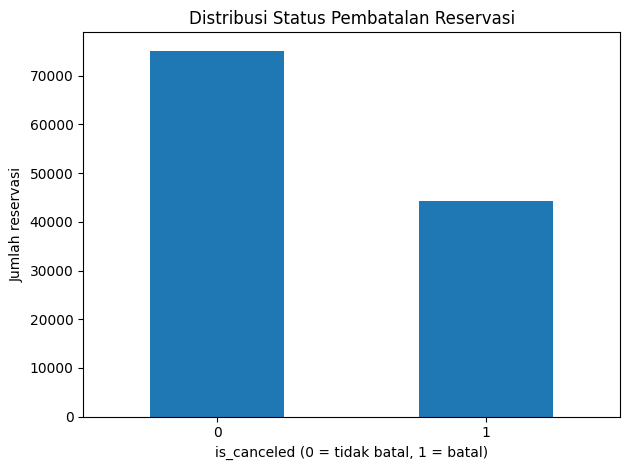

In [14]:
target_counts = df["is_canceled"].value_counts(dropna=False).sort_index()
target_percent = df["is_canceled"].value_counts(normalize=True, dropna=False).sort_index() * 100

target_summary = pd.DataFrame({
    "Jumlah": target_counts,
    "Persentase (%)": target_percent.round(2)
})
display(target_summary)

ax = target_counts.plot(kind="bar", rot=0)
ax.set_title("Distribusi Status Pembatalan Reservasi")
ax.set_xlabel("is_canceled (0 = tidak batal, 1 = batal)")
ax.set_ylabel("Jumlah reservasi")
plt.tight_layout()
plt.show()

**Interpretasi EDA 3.1 — lengkapi setelah kode dijalankan**

Tuliskan jumlah dan persentase tiap kelas. Jelaskan apakah distribusi kelas cukup seimbang atau tidak, serta implikasinya terhadap pemilihan metrik evaluasi.

## 3.2 Missing Values

In [ ]:
missing_summary = pd.DataFrame({
    "Jumlah Missing": df.isna().sum(),
    "Persentase Missing (%)": (df.isna().mean() * 100).round(2)
}).sort_values("Jumlah Missing", ascending=False)

display(missing_summary[missing_summary["Jumlah Missing"] > 0])

missing_plot = missing_summary[missing_summary["Jumlah Missing"] > 0].head(20)
if not missing_plot.empty:
    ax = missing_plot["Persentase Missing (%)"].sort_values().plot(kind="barh")
    ax.set_title("Kolom dengan Missing Values Terbanyak (maks. 20)")
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("Kolom")
    plt.tight_layout()
    plt.show()

**Interpretasi EDA 3.2 — lengkapi setelah kode dijalankan**

Sebutkan kolom dengan missing values terbanyak dan pertimbangkan makna nilai kosong pada tiap kolom. Temuan ini akan digunakan untuk merancang cleaning; nilai kosong tidak otomatis berarti data salah.

## 3.3 Duplikasi

In [ ]:
duplicate_count = int(df.duplicated().sum())
print("Jumlah baris duplikat identik:", duplicate_count)
print("Persentase terhadap seluruh baris (%):", round(duplicate_count / len(df) * 100, 2))

**Interpretasi EDA 3.3 — lengkapi setelah kode dijalankan**

Jelaskan jumlah duplikasi yang ditemukan. Sebelum menghapus baris, pertimbangkan bahwa baris identik belum tentu membuktikan adanya kesalahan pencatatan. Dokumentasikan alasan keputusan yang dipilih.

## 3.4 Distribusi Variabel Numerik

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
display(df[numeric_cols].describe().T)

selected_numeric = [
    col for col in ["lead_time", "adr", "booking_changes",
                    "total_of_special_requests", "previous_cancellations"]
    if col in df.columns
]

for col in selected_numeric:
    plt.figure()
    df[col].dropna().plot(kind="hist", bins=30)
    plt.title(f"Distribusi {col}")
    plt.xlabel(col)
    plt.ylabel("Frekuensi")
    plt.tight_layout()
    plt.show()

**Interpretasi EDA 3.4 — lengkapi per variabel**

Jelaskan bentuk distribusi, rentang nilai, kemungkinan skewness, dan nilai yang perlu diselidiki. Jangan langsung menghapus nilai ekstrem hanya karena jauh dari mayoritas data.

## 3.5 Tingkat Pembatalan Berdasarkan Kategori

In [ ]:
categorical_candidates = [
    col for col in ["hotel", "deposit_type", "market_segment",
                    "distribution_channel", "customer_type"]
    if col in df.columns
]

for col in categorical_candidates:
    rate = df.groupby(col, dropna=False)["is_canceled"].agg(
        jumlah_reservasi="size",
        tingkat_pembatalan="mean"
    )
    rate["tingkat_pembatalan_pct"] = rate["tingkat_pembatalan"] * 100
    display(rate.sort_values("tingkat_pembatalan_pct", ascending=False))

    ax = rate["tingkat_pembatalan_pct"].sort_values().plot(kind="barh")
    ax.set_title(f"Tingkat Pembatalan berdasarkan {col}")
    ax.set_xlabel("Tingkat pembatalan (%)")
    ax.set_ylabel(col)
    plt.tight_layout()
    plt.show()

**Interpretasi EDA 3.5 — lengkapi untuk setiap variabel**

Bandingkan tingkat pembatalan antarkategori dan perhatikan jumlah observasi di setiap kategori. Jelaskan pola yang tampak tanpa menyimpulkan hubungan sebab-akibat.

## 3.6 Korelasi Numerik
Korelasi hanya menunjukkan hubungan statistik tertentu dan tidak membuktikan sebab-akibat. Korelasi fitur terhadap target biner dapat dipakai sebagai eksplorasi awal, bukan satu-satunya dasar feature selection.

In [ ]:
corr_cols = [col for col in numeric_cols if df[col].nunique(dropna=True) > 1]
corr = df[corr_cols].corr(numeric_only=True)

if not corr.empty:
    fig, ax = plt.subplots(figsize=(12, 9))
    im = ax.imshow(corr, aspect="auto", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr.index)))
    ax.set_yticklabels(corr.index)
    ax.set_title("Korelasi Variabel Numerik")
    fig.colorbar(im, ax=ax, label="Korelasi")
    plt.tight_layout()
    plt.show()

**Interpretasi EDA 3.6 — lengkapi setelah kode dijalankan**

Tuliskan hubungan yang paling relevan, keterbatasan korelasi, dan apakah hasil tersebut memicu pemeriksaan lanjutan.

# 4. Cleaning dan Preprocessing

Keputusan cleaning harus merujuk pada temuan EDA. Pertahankan salinan data mentah agar perubahan dapat dilacak.

## 4.1 Ringkasan Kualitas Sebelum Cleaning

In [ ]:
def quality_summary(data):
    return pd.Series({
        "Jumlah baris": data.shape[0],
        "Jumlah kolom": data.shape[1],
        "Total missing values": int(data.isna().sum().sum()),
        "Baris duplikat identik": int(data.duplicated().sum())
    })

before_cleaning = quality_summary(df_raw)
display(before_cleaning.to_frame("Sebelum cleaning"))

## 4.2 Menentukan Kebijakan Cleaning
Isi keputusan setelah EDA. Untuk setiap tindakan, catat:
- masalah yang ditemukan;
- bukti dari output;
- tindakan yang dipilih;
- alasan memilih tindakan;
- dampak pada jumlah baris/kolom;
- risiko atau keterbatasan keputusan.

**Peringatan:** jangan langsung menghapus seluruh duplikasi atau mengimputasi semua missing values dengan satu nilai tanpa memeriksa maknanya.

In [ ]:
# Mulai dari salinan data mentah.
df_clean = df_raw.copy()

# TODO: terapkan keputusan cleaning yang sudah didokumentasikan.
# Contoh tindakan yang mungkin dipertimbangkan (jangan aktifkan tanpa alasan):
# 1. Menangani nilai kosong pada kolom yang dipilih.
# 2. Menyelidiki nilai ADR negatif atau nilai ekstrem.
# 3. Memutuskan apakah duplikasi identik perlu dihapus.
#
# Simpan setiap keputusan dengan komentar dan bandingkan hasil sebelum-sesudah.

## 4.3 Perbandingan Sebelum dan Sesudah

In [ ]:
comparison = pd.concat(
    [
        quality_summary(df_raw).rename("Sebelum"),
        quality_summary(df_clean).rename("Sesudah")
    ],
    axis=1
)
display(comparison)

**Interpretasi cleaning — lengkapi setelah tindakan dilakukan**

Jelaskan perubahan jumlah baris, kolom, missing values, dan duplikasi. Jika suatu masalah dipertahankan, jelaskan alasannya.

## 4.4 Pemeriksaan Nilai Ekstrem
Gunakan konteks domain dan hasil EDA untuk menentukan apakah nilai ekstrem merupakan kesalahan, kasus valid, atau perlu analisis sensitivitas.

In [ ]:
if "adr" in df_clean.columns:
    display(df_clean["adr"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).to_frame())
    print("Jumlah ADR negatif:", int((df_clean["adr"] < 0).sum()))

## 4.5 Persiapan Target dan Fitur
Target penelitian adalah `is_canceled`. Kolom yang mengungkap status akhir reservasi, seperti `reservation_status`, berpotensi menyebabkan data leakage dan tidak boleh menjadi fitur untuk memprediksi pembatalan sebelum hasil diketahui.

# 5. Feature Selection

Feature selection dilakukan dengan mempertimbangkan:
1. Relevansi dengan pertanyaan penelitian.
2. Ketersediaan informasi pada waktu prediksi.
3. Risiko data leakage.
4. Kualitas dan kelengkapan fitur.
5. Redundansi serta kebutuhan interpretasi model.

Buat tabel keputusan yang menjelaskan fitur dipakai, dibuang, atau dibuat. Keputusan awal harus ditinjau ulang berdasarkan hasil EDA dan tujuan prediksi.

In [ ]:
target_col = "is_canceled"

# Kolom yang secara konseptual berpotensi membocorkan status akhir.
potential_leakage_cols = [
    col for col in ["reservation_status", "reservation_status_date"]
    if col in df_clean.columns
]

print("Target:", target_col)
print("Kolom yang dikeluarkan dari kandidat fitur karena potensi leakage:",
      potential_leakage_cols)

# Contoh daftar awal kandidat fitur; tinjau dan sesuaikan setelah EDA.
candidate_features = [
    col for col in df_clean.columns
    if col != target_col and col not in potential_leakage_cols
]

display(pd.DataFrame({
    "Kandidat Fitur": candidate_features,
    "Tipe Data": [str(df_clean[col].dtype) for col in candidate_features],
    "Missing (%)": [(df_clean[col].isna().mean() * 100).round(2)
                    for col in candidate_features],
    "Nilai Unik": [df_clean[col].nunique(dropna=True)
                   for col in candidate_features]
}))

## 5.1 Rekayasa Fitur (Opsional)
Fitur baru hanya dibuat jika memiliki alasan yang jelas. Contoh kandidat:
- `total_nights` = `stays_in_weekend_nights` + `stays_in_week_nights`;
- `total_guests` = `adults` + `children` + `babies`.

Periksa missing values dan kewajaran nilainya terlebih dahulu. Pastikan fitur yang dibentuk tersedia pada waktu prediksi.

In [ ]:
df_model = df_clean.copy()

night_cols = ["stays_in_weekend_nights", "stays_in_week_nights"]
if all(col in df_model.columns for col in night_cols):
    df_model["total_nights"] = df_model[night_cols].sum(axis=1, min_count=len(night_cols))

guest_cols = ["adults", "children", "babies"]
if all(col in df_model.columns for col in guest_cols):
    # min_count mencegah penjumlahan menghasilkan nilai jika ada komponen yang hilang
    df_model["total_guests"] = df_model[guest_cols].sum(axis=1, min_count=len(guest_cols))

display(df_model[[c for c in ["total_nights", "total_guests"] if c in df_model.columns]].head())

# 6. Modeling

Bagian ini dilakukan setelah kebijakan cleaning dan daftar fitur final ditetapkan. Hindari melakukan imputasi, scaling, atau encoding menggunakan seluruh dataset sebelum pembagian train-test karena dapat menyebabkan leakage.

Rencana:
1. Pisahkan target dan fitur.
2. Tentukan strategi train-test split. Untuk tujuan prediksi masa depan, pertimbangkan pembagian berbasis waktu.
3. Bangun pipeline preprocessing agar transformasi dipelajari hanya dari data latih.
4. Bandingkan baseline dan model kandidat.
5. Catat parameter, random seed, dan alasan pemilihan model.

In [ ]:
# Template awal: lengkapi fitur final setelah keputusan feature selection.
# Jangan menjalankan modeling sebelum fitur final dan strategi split ditinjau.
#
# from sklearn.model_selection import train_test_split
# from sklearn.compose import ColumnTransformer
# from sklearn.pipeline import Pipeline
# from sklearn.impute import SimpleImputer
# from sklearn.preprocessing import OneHotEncoder, StandardScaler
# from sklearn.dummy import DummyClassifier
# from sklearn.linear_model import LogisticRegression
#
# target_col = "is_canceled"
# selected_features = [...]  # isi berdasarkan keputusan terdokumentasi
# X = df_model[selected_features]
# y = df_model[target_col]
#
# Pastikan target tidak missing dan hanya berisi label yang valid.
# Lakukan split terlebih dahulu, lalu fit preprocessing pada X_train saja.

# 7. Evaluation

Laporkan metrik pada data uji yang tidak digunakan untuk melatih model. Bandingkan kandidat model dengan baseline dan jelaskan trade-off antara precision dan recall untuk kelas pembatalan.

Metrik yang disarankan:
- confusion matrix;
- precision, recall, dan F1-score per kelas;
- ROC-AUC jika probabilitas prediksi tersedia dan kedua kelas ada;
- PR-AUC jika relevan untuk distribusi kelas;
- perbandingan dengan baseline.

Jangan memilih model hanya karena satu metrik tertinggi. Jelaskan konsekuensi false positive dan false negative dalam konteks hotel.

# 8. Konklusi

Lengkapi bagian ini setelah semua analisis dan eksperimen selesai.

## 8.1 Jawaban Pertanyaan Penelitian
Jawab setiap pertanyaan penelitian berdasarkan bukti dari EDA dan evaluasi.

## 8.2 Temuan Utama
Rangkum temuan yang paling kuat dan relevan, disertai angka atau hasil yang benar-benar diperoleh.

## 8.3 Keterbatasan
Bahas keterbatasan sumber data, missing values, representativitas, potensi bias, dan generalisasi model.

## 8.4 Saran
Berikan saran pengembangan yang sesuai dengan temuan, misalnya validasi pada periode lain atau simulasi biaya keputusan overbooking jika datanya memadai.

**Jangan menyatakan model siap digunakan di operasional nyata hanya berdasarkan evaluasi pada satu dataset.**

# Referensi dan Catatan Reproduksibilitas

- Dataset: Hotel Booking Demand, Kaggle: https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand
- Tambahkan dokumentasi/publikasi sumber dataset dan referensi metode yang benar-benar digunakan.
- Catat versi Python dan library yang digunakan.
- Pastikan notebook dapat dijalankan dari awal sampai akhir pada lingkungan baru.
- Jangan memasukkan file rahasia, token, atau data yang tidak boleh dibagikan ke repository publik.